In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_recall_curve, roc_curve,
    f1_score, confusion_matrix, classification_report
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTE

import shap

warnings.filterwarnings("ignore")

In [2]:
# Rutas
DATA_PROCESSED = Path("../data/processed/fraud_clean.csv")
FIG_DIR        = Path("../reports/figures/")
MDL_DIR        = Path("../models/")

MDL_DIR.mkdir(parents=True, exist_ok=True)

# Estilos
plt.rcParams.update({
    "figure.facecolor":  "white",
    "axes.facecolor":    "#F8F8F8",
    "axes.grid":         True,
    "grid.color":        "white",
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "font.size":         11,
    "figure.dpi":        120,
})

C_LEGIT = "#2196F3"
C_FRAUD = "#E53935"

# Cargar dataset
df = pd.read_csv(DATA_PROCESSED)

print(f"Dataset cargado: {df.shape[0]:,} filas × {df.shape[1]} columnas")
print(f"Tasa de fraude: {df['Class'].mean():.4%}")

Dataset cargado: 284,807 filas × 33 columnas
Tasa de fraude: 0.1727%


In [3]:
# Variables predictoras
v_cols = [f"V{i}" for i in range(1, 29)]

FEATURES = v_cols + ["log_amount", "hora"]
TARGET   = "Class"

X = df[FEATURES]
y = df[TARGET]

print(f"Features: {len(FEATURES)}")
print(f"Positivos (fraude): {y.sum():,}")
print(f"Negativos (legítima): {(y==0).sum():,}")
print(f"Scale pos weight: {(y==0).sum() / y.sum():.1f}")

Features: 30
Positivos (fraude): 492
Negativos (legítima): 284,315
Scale pos weight: 577.9


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Train: {X_train.shape[0]:,} filas")
print(f"Test:  {X_test.shape[0]:,} filas")
print(f"\nFraudes train: {y_train.sum()} ({y_train.mean():.4%})")
print(f"Fraudes test:  {y_test.sum()} ({y_test.mean():.4%})")

Train: 227,845 filas
Test:  56,962 filas

Fraudes train: 394 (0.1729%)
Fraudes test:  98 (0.1720%)


In [5]:
smote = SMOTE(
    sampling_strategy=0.1,  # llevar fraudes al 10% del train
    random_state=42,
    k_neighbors=5
)

X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print(f"Train original — Fraudes: {y_train.sum()} ({y_train.mean():.4%})")
print(f"Train SMOTE   — Fraudes: {y_train_sm.sum()} ({y_train_sm.mean():.4%})")
print(f"\nNuevas instancias sintéticas: {y_train_sm.sum() - y_train.sum():,}")

Train original — Fraudes: 394 (0.1729%)
Train SMOTE   — Fraudes: 22745 (9.0909%)

Nuevas instancias sintéticas: 22,351


In [6]:
SPW = (y_train == 0).sum() / (y_train == 1).sum()

modelos = {
    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        scale_pos_weight=SPW,
        random_state=42,
        n_jobs=-1,
        verbosity=0,
        eval_metric="aucpr",
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        is_unbalance=True,
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
    ),
}

resultados = {}

for nombre, modelo in modelos.items():
    print(f"Entrenando {nombre}...")
    modelo.fit(X_train_sm, y_train_sm)

    y_proba = modelo.predict_proba(X_test)[:, 1]
    y_pred  = (y_proba >= 0.5).astype(int)

    auc_roc = roc_auc_score(y_test, y_proba)
    auc_pr  = average_precision_score(y_test, y_proba)
    f1      = f1_score(y_test, y_pred)

    resultados[nombre] = {
        "modelo":  modelo,
        "y_proba": y_proba,
        "auc_roc": auc_roc,
        "auc_pr":  auc_pr,
        "f1":      f1,
    }

    print(f"  AUC-ROC : {auc_roc:.4f}")
    print(f"  AUC-PR  : {auc_pr:.4f} ← métrica principal")
    print(f"  F1-Score: {f1:.4f}\n")

Entrenando XGBoost...
  AUC-ROC : 0.9854
  AUC-PR  : 0.8538 ← métrica principal
  F1-Score: 0.4656

Entrenando LightGBM...
  AUC-ROC : 0.9795
  AUC-PR  : 0.8659 ← métrica principal
  F1-Score: 0.7311



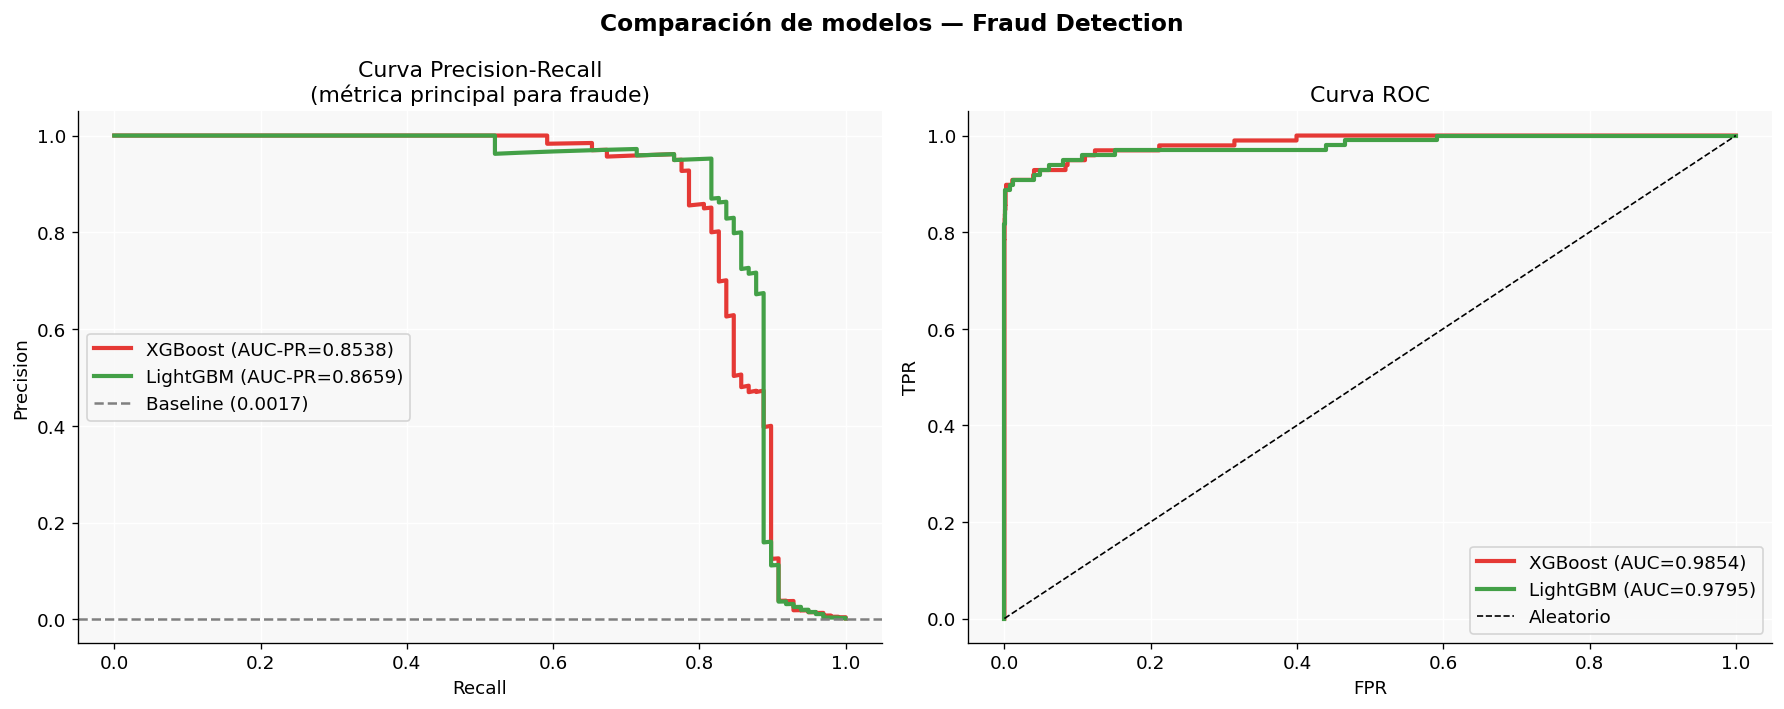

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
colores = {"XGBoost": "#E53935", "LightGBM": "#43A047"}

# Precision-Recall
ax = axes[0]
for nombre, r in resultados.items():
    prec, rec, _ = precision_recall_curve(y_test, r["y_proba"])
    ax.plot(rec, prec, linewidth=2.5,
            color=colores[nombre],
            label=f"{nombre} (AUC-PR={r['auc_pr']:.4f})")

ax.axhline(y_test.mean(), color="gray", linestyle="--",
           linewidth=1.5, label=f"Baseline ({y_test.mean():.4f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Curva Precision-Recall\n(métrica principal para fraude)")
ax.legend()

# ROC
ax = axes[1]
for nombre, r in resultados.items():
    fpr, tpr, _ = roc_curve(y_test, r["y_proba"])
    ax.plot(fpr, tpr, linewidth=2.5,
            color=colores[nombre],
            label=f"{nombre} (AUC={r['auc_roc']:.4f})")

ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Aleatorio")
ax.set_xlabel("FPR")
ax.set_ylabel("TPR")
ax.set_title("Curva ROC")
ax.legend()

plt.suptitle("Comparación de modelos — Fraud Detection",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "07_comparacion_modelos.png", bbox_inches="tight")
plt.show()

In [8]:
# Usar LightGBM como modelo final
modelo_final = resultados["LightGBM"]["modelo"]
y_proba_final = resultados["LightGBM"]["y_proba"]

# Calcular precision, recall y F1 para cada umbral
precision_arr, recall_arr, thresholds = precision_recall_curve(
    y_test, y_proba_final
)
f1_arr = 2 * precision_arr * recall_arr / (precision_arr + recall_arr + 1e-9)

# Umbral óptimo por F1
umbral_f1 = thresholds[np.argmax(f1_arr[:-1])]

# Umbral conservador — precision >= 90%
mask_90p = precision_arr[:-1] >= 0.90
umbral_90p = thresholds[mask_90p][0] if mask_90p.any() else umbral_f1

# Umbral agresivo — recall >= 85%
mask_85r = recall_arr[:-1] >= 0.85
umbral_85r = thresholds[mask_85r][-1] if mask_85r.any() else umbral_f1

print(f"Umbral F1 óptimo    : {umbral_f1:.4f}")
print(f"Umbral conservador  : {umbral_90p:.4f}")
print(f"Umbral agresivo     : {umbral_85r:.4f}")

Umbral F1 óptimo    : 0.9747
Umbral conservador  : 0.9526
Umbral agresivo     : 0.8058


In [9]:
y_pred_final = (y_proba_final >= umbral_f1).astype(int)

print("=" * 55)
print("EVALUACION FINAL — LightGBM")
print("=" * 55)
print(f"\nUmbral utilizado: {umbral_f1:.4f}")
print(f"\nClassification Report:")
print(classification_report(y_test, y_pred_final,
                            target_names=["Legitima", "Fraude"]))

# Matriz de confusion
cm = confusion_matrix(y_test, y_pred_final)
tn, fp, fn, tp = cm.ravel()

print(f"Verdaderos Positivos (TP): {tp} — fraudes detectados")
print(f"Falsos Negativos (FN)    : {fn} — fraudes perdidos")
print(f"Falsos Positivos (FP)    : {fp} — falsas alarmas")
print(f"Verdaderos Negativos (TN): {tn} — legítimas correctas")

EVALUACION FINAL — LightGBM

Umbral utilizado: 0.9747

Classification Report:
              precision    recall  f1-score   support

    Legitima       1.00      1.00      1.00     56864
      Fraude       0.95      0.82      0.88        98

    accuracy                           1.00     56962
   macro avg       0.98      0.91      0.94     56962
weighted avg       1.00      1.00      1.00     56962

Verdaderos Positivos (TP): 80 — fraudes detectados
Falsos Negativos (FN)    : 18 — fraudes perdidos
Falsos Positivos (FP)    : 4 — falsas alarmas
Verdaderos Negativos (TN): 56860 — legítimas correctas


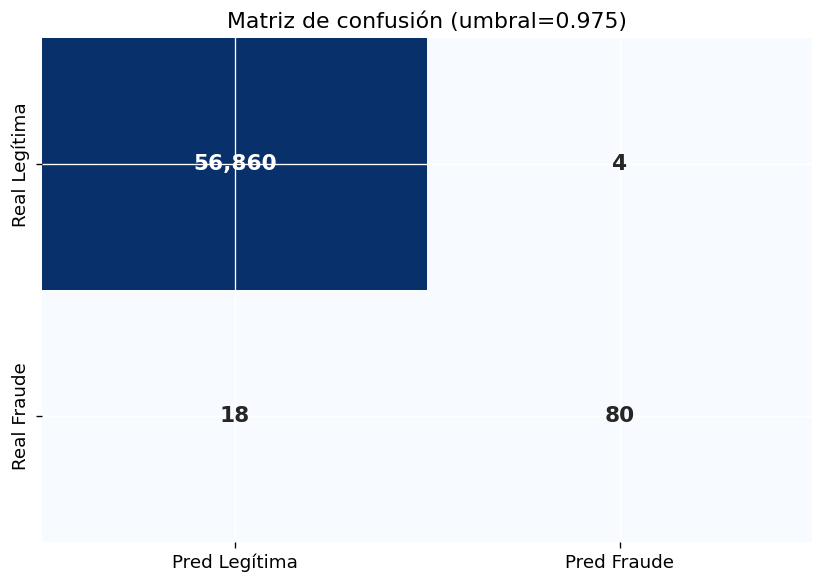


Impacto económico estimado:
  Fraude detectado  : €7,901.31
  Fraude no detectado: €2,746.62


In [10]:
fig, ax = plt.subplots(figsize=(7, 5))

sns.heatmap(
    cm, annot=True, fmt=",",
    cmap="Blues",
    xticklabels=["Pred Legítima", "Pred Fraude"],
    yticklabels=["Real Legítima", "Real Fraude"],
    ax=ax, cbar=False,
    annot_kws={"size": 13, "weight": "bold"}
)
ax.set_title(f"Matriz de confusión (umbral={umbral_f1:.3f})")

plt.tight_layout()
plt.savefig(FIG_DIR / "08_confusion_matrix.png", bbox_inches="tight")
plt.show()

# Impacto económico
monto_fraude_detectado = df.loc[
    y_test[y_pred_final==1].index, "Amount"
].sum()
monto_fraude_perdido = df.loc[
    y_test[(y_pred_final==0) & (y_test==1)].index, "Amount"
].sum()

print(f"\nImpacto económico estimado:")
print(f"  Fraude detectado  : €{monto_fraude_detectado:,.2f}")
print(f"  Fraude no detectado: €{monto_fraude_perdido:,.2f}")

In [11]:
# SHAP sobre muestra del test para eficiencia
sample_idx = np.random.choice(len(X_test), 500, replace=False)
X_test_sample = X_test.iloc[sample_idx]

explainer   = shap.TreeExplainer(modelo_final)
shap_values = explainer.shap_values(X_test_sample)

# Importancia media
shap_importance = pd.DataFrame({
    "feature":   FEATURES,
    "mean_shap": np.abs(shap_values).mean(axis=0)
}).sort_values("mean_shap", ascending=False)

print("Top 10 features por importancia SHAP:")
print(shap_importance.head(10).to_string(index=False))

Top 10 features por importancia SHAP:
feature  mean_shap
     V4   1.166523
    V14   0.908649
     V1   0.850781
     V8   0.519296
    V18   0.507586
    V22   0.414705
    V12   0.389914
    V24   0.386390
     V3   0.357516
     V2   0.322683


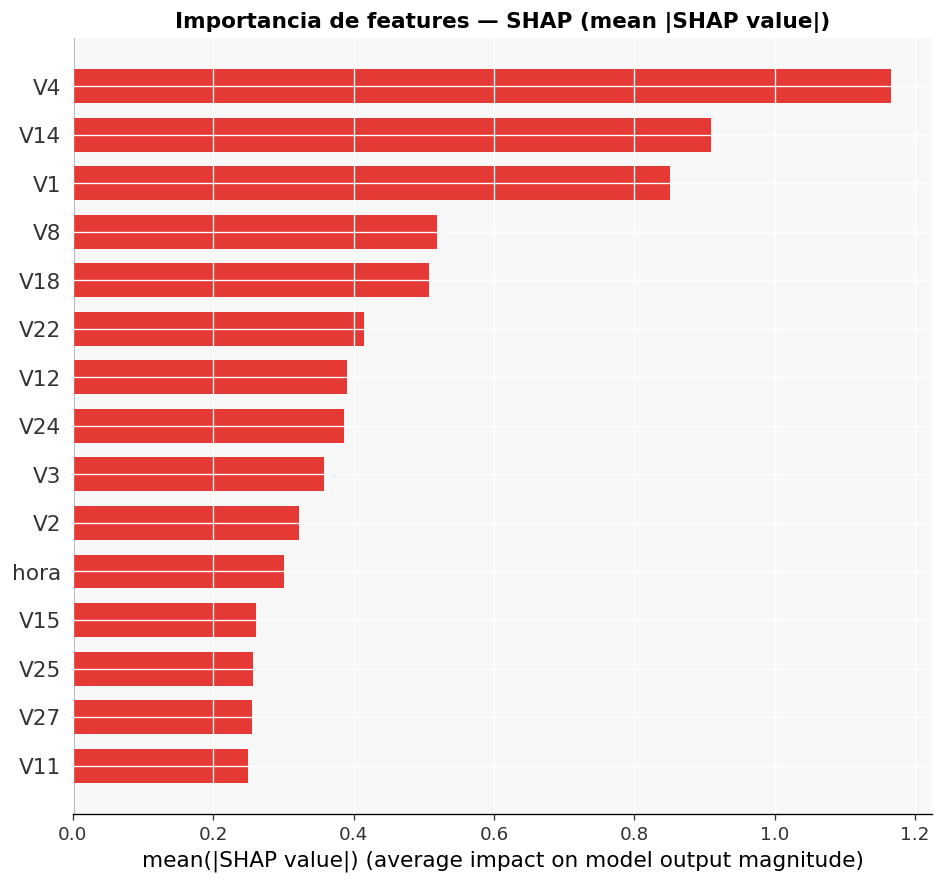

In [12]:
fig, ax = plt.subplots(figsize=(9, 7))
shap.summary_plot(
    shap_values,
    X_test_sample,
    feature_names=FEATURES,
    plot_type="bar",
    max_display=15,
    show=False,
    color=C_FRAUD,
)
ax.set_title("Importancia de features — SHAP (mean |SHAP value|)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "09_shap_importancia.png", bbox_inches="tight")
plt.show()

In [13]:
joblib.dump({
    "modelo":        modelo_final,
    "features":      FEATURES,
    "umbral_f1":     umbral_f1,
    "umbral_90prec": umbral_90p,
    "umbral_85rec":  umbral_85r,
    "metricas": {
        "auc_pr":    round(resultados["LightGBM"]["auc_pr"], 4),
        "auc_roc":   round(resultados["LightGBM"]["auc_roc"], 4),
        "f1":        round(f1_score(y_test, y_pred_final), 4),
        "precision": round(tp / (tp + fp), 4),
        "recall":    round(tp / (tp + fn), 4),
    },
    "shap_importance": shap_importance,
}, MDL_DIR / "fraud_model.pkl")

print("Modelo guardado → models/fraud_model.pkl ✓")

Modelo guardado → models/fraud_model.pkl ✓


In [14]:
print("=" * 60)
print("RESUMEN EJECUTIVO — Fraud Detection (Parte 2)")
print("=" * 60)
print(f"\nModelo: LightGBM + SMOTE")
print(f"Features: {len(FEATURES)} (28 PCA + log_amount + hora)")
print(f"\nComparación de modelos:")
for nombre, r in resultados.items():
    print(f"  {nombre:<10} — AUC-PR: {r['auc_pr']:.4f} | "
          f"AUC-ROC: {r['auc_roc']:.4f} | F1: {r['f1']:.4f}")
print(f"\nMétricas modelo final (LightGBM):")
print(f"  AUC-PR    : {resultados['LightGBM']['auc_pr']:.4f}")
print(f"  AUC-ROC   : {resultados['LightGBM']['auc_roc']:.4f}")
print(f"  Precision : {tp/(tp+fp):.4f}")
print(f"  Recall    : {tp/(tp+fn):.4f}")
print(f"  F1-Score  : {f1_score(y_test, y_pred_final):.4f}")
print(f"\nUmbrales disponibles:")
print(f"  F1 óptimo   : {umbral_f1:.4f}")
print(f"  Conservador : {umbral_90p:.4f}")
print(f"  Agresivo    : {umbral_85r:.4f}")
print(f"\nImpacto económico (test set):")
print(f"  Fraude detectado    : €{monto_fraude_detectado:,.2f}")
print(f"  Fraude no detectado : €{monto_fraude_perdido:,.2f}")
print(f"\nTop 5 features por SHAP:")
for _, row in shap_importance.head(5).iterrows():
    print(f"  {row['feature']:<12}: {row['mean_shap']:.4f}")
print("=" * 60)

RESUMEN EJECUTIVO — Fraud Detection (Parte 2)

Modelo: LightGBM + SMOTE
Features: 30 (28 PCA + log_amount + hora)

Comparación de modelos:
  XGBoost    — AUC-PR: 0.8538 | AUC-ROC: 0.9854 | F1: 0.4656
  LightGBM   — AUC-PR: 0.8659 | AUC-ROC: 0.9795 | F1: 0.7311

Métricas modelo final (LightGBM):
  AUC-PR    : 0.8659
  AUC-ROC   : 0.9795
  Precision : 0.9524
  Recall    : 0.8163
  F1-Score  : 0.8791

Umbrales disponibles:
  F1 óptimo   : 0.9747
  Conservador : 0.9526
  Agresivo    : 0.8058

Impacto económico (test set):
  Fraude detectado    : €7,901.31
  Fraude no detectado : €2,746.62

Top 5 features por SHAP:
  V4          : 1.1665
  V14         : 0.9086
  V1          : 0.8508
  V8          : 0.5193
  V18         : 0.5076
